# Network Intrusion Detection on UNSW-NB15
MOD011115 Advanced Topics in Cyber Security | Student ID: 2515985

**Data:** the official UNSW-NB15 partitioned files `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` (UNSW Canberra).

**Pipeline:** load and check data (1, 1b) -> prepare features (2) -> baseline model and preprocessing fix (3) -> Random Forest and XGBoost (4) -> multi-seed and deduplicated tests (5) -> results and figures (6) -> investigation (7).

The prompt shown before each major stage is the instruction given to the GenAI tool for that stage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

In [2]:
# Environment versions (needed to reproduce the results)
import sys, sklearn, xgboost
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__)

Python: 3.9.6 | NumPy: 2.0.2 | pandas: 2.3.3
scikit-learn: 1.6.1 | XGBoost: 2.1.4


## Stage 1: Dataset Loading and Understanding
**Goal:** Load the official UNSW-NB15 train and test files and check their integrity before modelling.

**Prompt given to GenAI:**
"I'm using the UNSW-NB15 official training and testing CSVs for a network intrusion detection project. Write pandas code that loads both files and prints: shape, column names and dtypes, missing values per column, number of duplicate rows, the binary `label` distribution, and the `attack_cat` distribution for each file. Add bar charts for both distributions. Also print the set of categorical column values for `proto`, `service` and `state` in train and test, and flag any category that appears in only one file. Comment each step."


===== TRAIN =====
Shape: (175341, 45)

Column dtypes:
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl     

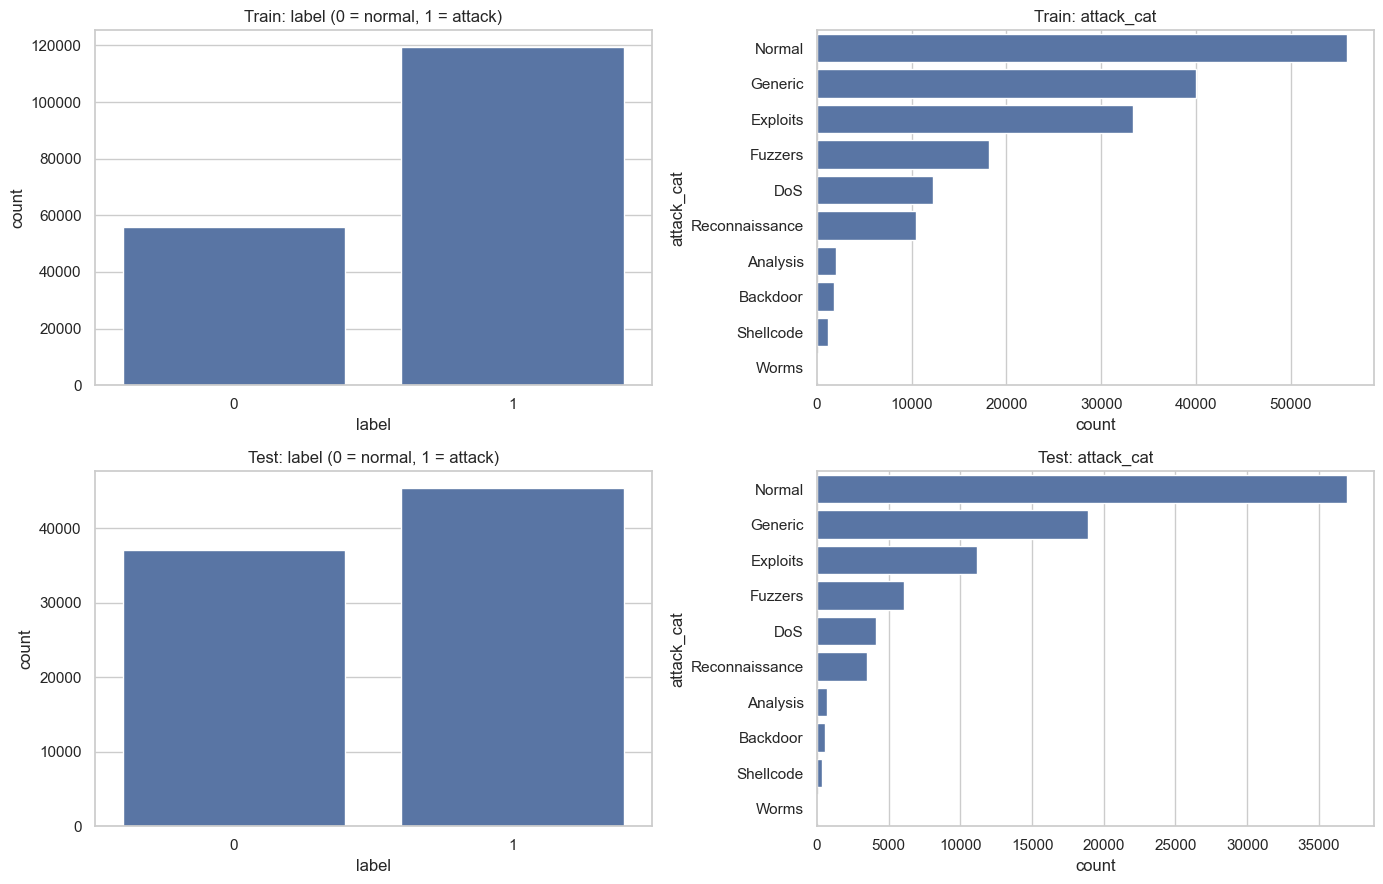


proto: 133 train, 131 test values
  only in train: ['icmp', 'rtp']
  only in test:  []

service: 13 train, 13 test values
  only in train: []
  only in test:  []

state: 9 train, 7 test values
  only in train: ['ECO', 'PAR', 'URN', 'no']
  only in test:  ['ACC', 'CLO']


In [3]:
TRAIN_PATH = "UNSW_NB15_training-set.csv"
TEST_PATH = "UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

for name, df in [("TRAIN", train_df), ("TEST", test_df)]:
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("\nColumn dtypes:")
    print(df.dtypes)
    print("\nMissing values (columns with any):")
    missing = df.isna().sum()
    print(missing[missing > 0] if missing.any() else "None")
    # 'id' is unique per row, so exclude it or duplicates will always read 0
    dup = df.drop(columns=["id"]).duplicated().sum()
    print("\nDuplicate rows (ignoring id):", dup)
    print("\nBinary label distribution:")
    print(df["label"].value_counts().sort_index())
    print(df["label"].value_counts(normalize=True).sort_index().round(4))
    print("\nattack_cat distribution:")
    print(df["attack_cat"].value_counts())

# Bar charts: label and attack_cat for each file
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, (name, df) in enumerate([("Train", train_df), ("Test", test_df)]):
    sns.countplot(x="label", data=df, ax=axes[i, 0])
    axes[i, 0].set_title(f"{name}: label (0 = normal, 1 = attack)")
    order = df["attack_cat"].value_counts().index
    sns.countplot(y="attack_cat", data=df, order=order, ax=axes[i, 1])
    axes[i, 1].set_title(f"{name}: attack_cat")
plt.tight_layout()
plt.show()

# Categorical values present in only one of the two files
for col in ["proto", "service", "state"]:
    tr, te = set(train_df[col].unique()), set(test_df[col].unique())
    print(f"\n{col}: {len(tr)} train, {len(te)} test values")
    print("  only in train:", sorted(tr - te))
    print("  only in test: ", sorted(te - tr))

**Validation note:**
- **Checked:** shapes, NaNs, duplicates, label balance, categories found in only one file.
- **Found:** 175,341 × 45 and 82,332 × 45 (official sizes); no NaNs; duplicates 38.6% (train) and 32.1% (test); attack share 68.1% vs 55.1%; Worms only 130 / 44 rows; some `proto` and `state` values appear in one file only.
- **Why it matters:** duplicates can inflate scores, the label shift and rare categories limit comparability, and `handle_unknown="ignore"` copes with unseen categories.

### Stage 1b: Duplicate and Overlap Validation
**Goal:** Check whether duplicate rows carry conflicting labels and how much of the test set also appears in training.

**Prompt given to GenAI:**
"Using `train_df` and `test_df`, check (1) whether any feature-identical rows in train have different `label` values, (2) how many test rows have an exact feature match in the training set, excluding `id`, `attack_cat` and `label`, and (3) the share of `service` values equal to '-'. Print counts and percentages."

In [4]:
feat_cols = [c for c in train_df.columns if c not in ("id", "attack_cat", "label")]

# 1. Feature-identical rows in train that carry different labels
conflicts = train_df.groupby(feat_cols)["label"].nunique()
print("Feature-identical groups with conflicting labels (train):", (conflicts > 1).sum())

# 2. Test rows that also appear (feature-wise) in the training set
train_keys = train_df[feat_cols].drop_duplicates()
merged = test_df.merge(train_keys, on=feat_cols, how="left", indicator=True)
overlap = (merged["_merge"] == "both").sum()
print(f"Test rows with an exact match in train: {overlap} ({overlap / len(test_df):.2%})")

# 3. 'service' uses '-' for none, which isn't counted as missing
print("service == '-' (train):", f"{(train_df['service'] == '-').mean():.2%}")

Feature-identical groups with conflicting labels (train): 229
Test rows with an exact match in train: 8541 (10.37%)
service == '-' (train): 53.71%


**Validation note:**
- **Checked:** conflicting labels, train/test overlap, share of `service` = '-'.
- **Found:** 229 conflicting-label groups; 8,541 test rows (10.37%) match training rows; `service` = '-' in 53.71% of train rows.
- **Why it matters:** conflicts cap achievable accuracy, overlap makes scores optimistic, and '-' is a category, not missing data.

## Stage 2: Data Preparation
**Goal:** Build leakage-safe features: drop identifiers, keep `attack_cat` aside for analysis only, one-hot encode categoricals, scale numeric features, and fit all transformers on the training data only. Include an optional deduplication switch and an optional log transform.

**Prompt given to GenAI:**
"Write a function `prepare(train_df, test_df, dedupe=False, log_transform=False)` using scikit-learn. Drop `id` and `attack_cat` from the features but keep the test `attack_cat` separately for analysis. One-hot encode `proto`, `service` and `state` with `handle_unknown='ignore'`, scale the numeric columns with RobustScaler (preceded by np.log1p when `log_transform=True`, after asserting the columns are non-negative), and fit the ColumnTransformer on the training data only. If `dedupe=True`, remove duplicate feature rows in train and test and drop test rows whose features also appear in train. Return the processed matrices, labels, the test attack categories and the feature names."

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer

CAT_COLS = ["proto", "service", "state"]
DROP_COLS = ["id", "attack_cat"]
TARGET = "label"

def prepare(train_df, test_df, dedupe=False, log_transform=False):
    tr, te = train_df.copy(), test_df.copy()
    feat_cols = [c for c in tr.columns if c not in DROP_COLS + [TARGET]]

    if dedupe:
        tr = tr.drop_duplicates(subset=feat_cols)
        te = te.drop_duplicates(subset=feat_cols)
        keys = tr[feat_cols].drop_duplicates()
        te = te.merge(keys, on=feat_cols, how="left", indicator=True)
        te = te[te["_merge"] == "left_only"].drop(columns="_merge")

    tr, te = tr.reset_index(drop=True), te.reset_index(drop=True)
    X_train, y_train = tr[feat_cols], tr[TARGET].values
    X_test, y_test = te[feat_cols], te[TARGET].values
    test_attack_cat = te["attack_cat"].values          # analysis only, never a feature

    num_cols = [c for c in feat_cols if c not in CAT_COLS]

    if log_transform:
        # log1p is only valid for values >= 0, so check first
        assert (X_train[num_cols] >= 0).all().all() and (X_test[num_cols] >= 0).all().all()
        num_pipe = Pipeline([
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", RobustScaler()),
        ])
    else:
        num_pipe = RobustScaler()

    pre = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])
    Xtr = pre.fit_transform(X_train)    # fit on TRAIN only
    Xte = pre.transform(X_test)         # transform only on test
    names = list(pre.get_feature_names_out())
    return Xtr, Xte, y_train, y_test, test_attack_cat, names

# First run: raw scaling only (no log transform)
Xtr_raw, Xte_raw, ytr, yte, te_cat, names_raw = prepare(train_df, test_df, log_transform=False)

# Validation checks
print("Train matrix:", Xtr_raw.shape, "| Test matrix:", Xte_raw.shape)
print("Same column count:", Xtr_raw.shape[1] == Xte_raw.shape[1])
print("NaNs in train/test:", np.isnan(Xtr_raw).sum(), np.isnan(Xte_raw).sum())
print("Forbidden columns present:", [n for n in names_raw
      if "attack_cat" in n or n.endswith("label") or n.split("__")[-1] == "id"])
print("Test attack_cat length matches:", len(te_cat) == Xte_raw.shape[0])
print("Label counts train:", np.bincount(ytr), "test:", np.bincount(yte))

Train matrix: (175341, 194) | Test matrix: (82332, 194)
Same column count: True
NaNs in train/test: 0 0
Forbidden columns present: []
Test attack_cat length matches: True
Label counts train: [ 56000 119341] test: [37000 45332]


**Validation note:**
- **Checked:** matrix shapes, NaNs, forbidden columns, label counts.
- **Found:** 194 columns in train and test (39 numeric + 155 one-hot); no NaNs; no `id`, `attack_cat` or `label` among the features; label counts unchanged.
- **Why it matters:** fitting on train only prevents leakage, and test-only categories become zeros.

## Stage 3: Model 1 Development (Logistic Regression baseline)
**Goal:** Define a reusable evaluation helper, then train a linear baseline. It is trained first on the raw matrices (3a), the problem found is diagnosed and fixed (3b), and the baseline is retrained on the fixed matrices (3c).

**Prompt given to GenAI:**
"Write a reusable function `evaluate(name, y_true, y_pred, y_score)` that returns accuracy, precision, recall, F1, ROC-AUC and False Alarm Rate (FP / (FP + TN)), and prints the confusion matrix with TN, FP, FN, TP labelled."

In [6]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, accuracy_score, confusion_matrix)

def evaluate(name, y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    res = {"model": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "precision": precision_score(y_true, y_pred),
           "recall": recall_score(y_true, y_pred),
           "f1": f1_score(y_true, y_pred),
           "roc_auc": roc_auc_score(y_true, y_score),
           "FAR": fp / (fp + tn)}
    print(f"\n{name}  (TN={tn}, FP={fp}, FN={fn}, TP={tp})")
    for k, v in res.items():
        if k != "model":
            print(f"  {k:10s}: {v:.4f}")
    return res

### Stage 3a: Baseline on the raw (unfixed) features
**Prompt given to GenAI:**
"Train a scikit-learn LogisticRegression (max_iter=1000, class_weight='balanced', random_state=SEED) on `Xtr_raw`, report the number of iterations used and training time, evaluate it with `evaluate()`, and recompute false alarm rate and recall by hand from the confusion matrix."

In [7]:
# Warnings are deliberately left visible here: they are the evidence of the problem
t0 = time.time()
lr_before = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr_before.fit(Xtr_raw, ytr)
print(f"Training time: {time.time() - t0:.1f}s | iterations used: {lr_before.n_iter_[0]} (limit 1000)")

pred_b = lr_before.predict(Xte_raw)
score_b = lr_before.predict_proba(Xte_raw)[:, 1]
res_before = evaluate("Logistic Regression (before fix)", yte, pred_b, score_b)

tn, fp, fn, tp = confusion_matrix(yte, pred_b).ravel()
print("\nManual check -> FAR:", round(fp / (fp + tn), 4), "| Recall:", round(tp / (tp + fn), 4))

/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * wei

Training time: 11.3s | iterations used: 1000 (limit 1000)

Logistic Regression (before fix)  (TN=22907, FP=14093, FN=4702, TP=40630)
  accuracy  : 0.7717
  precision : 0.7425
  recall    : 0.8963
  f1        : 0.8122
  roc_auc   : 0.8646
  FAR       : 0.3809

Manual check -> FAR: 0.3809 | Recall: 0.8963


/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nahidameen

**Problem found:**
- **Checked:** convergence, test performance, a hand recomputation of FAR and recall.
- **Found:** 1,000 iterations (the limit) with a `ConvergenceWarning`; accuracy 0.7717, FAR 0.3809; the hand check matched.
- **Why it matters:** an unfinished optimiser gives an unfair baseline, so I did not trust this result.

### Stage 3b: Preprocessing fix (log transform)
**Goal:** Heavy-tailed numeric features (e.g. byte counts and loads) were still very large after RobustScaler, and the solver did not converge. Apply log1p before scaling.

**Prompt given to GenAI:**
"Logistic Regression did not converge after RobustScaler on heavy-tailed network features. Add an optional `log_transform` flag to `prepare()` that applies np.log1p to the numeric columns before RobustScaler inside a scikit-learn Pipeline, asserting the values are non-negative first. Print the largest absolute value in the transformed training matrix with and without the transform."

In [8]:
worst = np.argsort(np.abs(Xtr_raw).max(axis=0))[::-1][:5]
print("Largest |value| WITHOUT log1p:", float(np.abs(Xtr_raw).max()))
print("Worst columns:", [(names_raw[i], round(float(np.abs(Xtr_raw[:, i]).max()))) for i in worst])

# From here on, Xtr / Xte are the log-transformed matrices used by every later stage
Xtr, Xte, ytr, yte, te_cat, feat_names = prepare(train_df, test_df, log_transform=True)

print("\nLargest |value| WITH log1p:   ", float(np.abs(Xtr).max()))
print("Shapes:", Xtr.shape, Xte.shape, "| NaNs:", np.isnan(Xtr).sum(), np.isnan(Xte).sum())

Largest |value| WITHOUT log1p: 6558056.0
Worst columns: [('num__response_body_len', 6558056), ('num__dbytes', 13299), ('num__sbytes', 9942), ('num__dloss', 2742), ('num__djit', 2517)]

Largest |value| WITH log1p:    49.19328011234734
Shapes: (175341, 194) (82332, 194) | NaNs: 0 0


**Fix:**
- **Checked:** largest |value| before and after `log1p`, shapes, NaNs.
- **Found:** 6,558,056 (`response_body_len`) without `log1p`; 49.19 with it; shapes unchanged, no NaNs.
- **Why it matters:** `log1p` compresses heavy tails while keeping the order of values, so tree models should be unaffected (expected, not tested).

### Stage 3c: Baseline on the fixed features
**Prompt given to GenAI:**
"Retrain the same LogisticRegression on the log-transformed matrices `Xtr` and `Xte`, store its predictions as `lr_pred` and `lr_score`, create the `results` list, append the evaluation, and repeat the hand-computed false alarm rate check."

In [9]:
results = []     # defined once, here, before any model is added

t0 = time.time()
lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr.fit(Xtr, ytr)
print(f"Training time: {time.time() - t0:.1f}s | iterations used: {lr.n_iter_[0]} (limit 1000)")

lr_pred = lr.predict(Xte)
lr_score = lr.predict_proba(Xte)[:, 1]
results.append(evaluate("Logistic Regression", yte, lr_pred, lr_score))

tn, fp, fn, tp = confusion_matrix(yte, lr_pred).ravel()
print("\nManual check -> FAR:", round(fp / (fp + tn), 4), "| Recall:", round(tp / (tp + fn), 4))
print("Predicted attack share:", round(lr_pred.mean(), 4), "| True attack share:", round(yte.mean(), 4))

/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * wei

Training time: 2.6s | iterations used: 252 (limit 1000)

Logistic Regression  (TN=28719, FP=8281, FN=2758, TP=42574)
  accuracy  : 0.8659
  precision : 0.8372
  recall    : 0.9392
  f1        : 0.8852
  roc_auc   : 0.9664
  FAR       : 0.2238

Manual check -> FAR: 0.2238 | Recall: 0.9392
Predicted attack share: 0.6177 | True attack share: 0.5506


/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nahidameen/ARU/Sem 1/Advanced Topics in Cyber Security/atcs-project/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  

**Result after the fix:**
- **Checked:** convergence, performance, hand-computed FAR and recall.
- **Found:** converged in 252 iterations; accuracy 0.8659, recall 0.9392, FAR 0.2238, ROC-AUC 0.9664 (before: 0.7717, FAR 0.3809); the hand check matched.
- **Why it matters:** preprocessing changed the result as much as the model would, and this is the baseline for later stages.

### Stage 3d: Warning diagnostic
**Goal:** The fixed model converged but `RuntimeWarning` messages (divide by zero, overflow, invalid value in matmul) still appeared. Check whether they come from the data or model, or from the NumPy installation.

**Prompt given to GenAI:**
"My Logistic Regression converged, but scikit-learn still prints RuntimeWarnings in matmul even though the largest value in my feature matrix is small. Write a diagnostic cell that prints the NumPy version, checks that the train and test matrices and model coefficients are finite, tests whether plain matrix multiplication on random data raises the same warnings, and recomputes the predicted probabilities without the @ operator to compare with predict_proba."

In [10]:
import warnings
from scipy.special import expit

print("NumPy:", np.__version__)
print("Train/test finite:", np.isfinite(Xtr).all(), np.isfinite(Xte).all())
print("Model coefficients finite:", np.isfinite(lr.coef_).all(),
      "| max |coef|:", float(np.abs(lr.coef_).max()))

# Does plain matrix multiplication on harmless random data raise the same warnings?
a = np.random.rand(1000, 194)
w = np.random.rand(194)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    _ = a @ w
print("Warnings on harmless random data:", [str(c.message) for c in caught])

# Recompute the probabilities without the @ operator and compare
z = (Xte * lr.coef_[0]).sum(axis=1) + lr.intercept_[0]
manual_prob = expit(z)
print("Max difference vs predict_proba:", float(np.abs(manual_prob - lr_score).max()))
print("Predictions identical:", np.array_equal((manual_prob >= 0.5).astype(int), lr_pred))

NumPy: 2.0.2
Train/test finite: True True
Model coefficients finite: True | max |coef|: 15.173537626073498
Warnings on harmless random data: ['divide by zero encountered in matmul', 'overflow encountered in matmul', 'invalid value encountered in matmul']
Max difference vs predict_proba: 2.4424906541753444e-15
Predictions identical: True


**Conclusion:**
- **Checked:** whether the matmul warnings come from the data, the model or NumPy.
- **Found:** data and coefficients finite (max |coef| 15.17); random data raises the same warnings; manual probabilities differ from `predict_proba` by 2.4e-15 with identical predictions.
- **Why it matters:** the results are unaffected; the likely cause is NumPy 2.0.2 (not proven).

## Stage 4: Model 2 and Model 3 Development (Random Forest and XGBoost)
**Goal:** Train two tree-ensemble models on the same prepared features as the baseline, with the same class-imbalance policy, and evaluate them with the same function.

**Prompt given to GenAI:**
"Using the prepared matrices `Xtr`, `Xte`, `ytr`, `yte`, train (1) a scikit-learn RandomForestClassifier (n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=SEED) and (2) an XGBClassifier (n_estimators=200, learning_rate=0.1, max_depth=6, eval_metric='logloss', n_jobs=-1, random_state=SEED) with scale_pos_weight set to the negative-to-positive ratio in the training labels so that the class weighting matches the Random Forest's. Time each training run, evaluate both with my `evaluate()` function, append the results to the `results` list, and print a hand-computed false alarm rate to verify each one."

In [11]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# ---- Model 2: Random Forest ----
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(Xtr, ytr)
print(f"Random Forest training time: {time.time() - t0:.1f}s")
rf_pred = rf.predict(Xte)
rf_score = rf.predict_proba(Xte)[:, 1]
results.append(evaluate("Random Forest", yte, rf_pred, rf_score))

# ---- Model 3: XGBoost ----
neg, pos = np.bincount(ytr)
spw = neg / pos     # same "balance the classes" intent as class_weight="balanced"
print(f"\nscale_pos_weight = {spw:.4f}")

t0 = time.time()
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, eval_metric="logloss",
                    scale_pos_weight=spw, n_jobs=-1, random_state=SEED)
xgb.fit(Xtr, ytr)
print(f"XGBoost training time: {time.time() - t0:.1f}s")
xgb_pred = xgb.predict(Xte)
xgb_score = xgb.predict_proba(Xte)[:, 1]
results.append(evaluate("XGBoost", yte, xgb_pred, xgb_score))

# ---- Validation: manual FAR and recall for each tree model ----
for name, pred in [("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    print(f"\n{name} manual check -> FAR: {fp/(fp+tn):.4f} | Recall: {tp/(tp+fn):.4f}"
          f" | predicted attack share: {pred.mean():.4f} (true: {yte.mean():.4f})")
print("\nModels in results:", [r["model"] for r in results])

Random Forest training time: 5.7s

Random Forest  (TN=26945, FP=10055, FN=594, TP=44738)
  accuracy  : 0.8707
  precision : 0.8165
  recall    : 0.9869
  f1        : 0.8936
  roc_auc   : 0.9803
  FAR       : 0.2718

scale_pos_weight = 0.4692
XGBoost training time: 1.5s

XGBoost  (TN=31150, FP=5850, FN=1665, TP=43667)
  accuracy  : 0.9087
  precision : 0.8819
  recall    : 0.9633
  f1        : 0.9208
  roc_auc   : 0.9848
  FAR       : 0.1581

Random Forest manual check -> FAR: 0.2718 | Recall: 0.9869 | predicted attack share: 0.6655 (true: 0.5506)

XGBoost manual check -> FAR: 0.1581 | Recall: 0.9633 | predicted attack share: 0.6014 (true: 0.5506)

Models in results: ['Logistic Regression', 'Random Forest', 'XGBoost']


**Validation note:**
- **Checked:** hand-computed FAR and recall, predicted versus true attack share, one entry per model in `results`.
- **Found:** Random Forest accuracy 0.8707, recall 0.9869, FAR 0.2718; XGBoost 0.9087, 0.9633, 0.1581; hand checks matched; predicted attack share 66.6% (RF) and 60.1% (XGBoost) vs 55.1% true.
- **Why it matters:** the imbalance policy is matched across models, and most errors are false alarms.

## Stage 5: Testing and Evaluation (multiple seeds + deduplicated sensitivity test)
**Goal:** (1) Check that model differences are stable across random seeds. (2) Measure how much the official test scores depend on duplicate rows and train/test overlap.

**Prompt given to GenAI:**
"Write a function `run_experiment(Xtr, Xte, ytr, yte, seeds, label)` that, for each seed, trains Logistic Regression (max_iter=1000, class_weight='balanced'), Random Forest (n_estimators=200, class_weight='balanced') and XGBoost (n_estimators=200, learning_rate=0.1, max_depth=6, scale_pos_weight = negatives/positives) with that seed, and returns a DataFrame with accuracy, precision, recall, F1, ROC-AUC and false alarm rate per model and seed. Run it for 5 seeds on (a) the official split and (b) the deduplicated split from my `prepare(..., dedupe=True, log_transform=True)`. Print the shape and label counts of each dataset, and summarise mean and standard deviation per model and setting."

In [12]:
SEEDS = [42, 7, 123, 2024, 99]

def metrics(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_score),
            "FAR": fp / (fp + tn)}

def make_models(seed, spw):
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=seed),
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, eval_metric="logloss",
                                 scale_pos_weight=spw, n_jobs=-1, random_state=seed),
    }

def run_experiment(Xtr, Xte, ytr, yte, seeds, label):
    neg, pos = np.bincount(ytr)
    spw = neg / pos
    rows = []
    for seed in seeds:
        for name, model in make_models(seed, spw).items():
            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
            score = model.predict_proba(Xte)[:, 1]
            rows.append({"setting": label, "seed": seed, "model": name, **metrics(yte, pred, score)})
        print(f"  {label}: seed {seed} done")
    return pd.DataFrame(rows)

# Data versions (both use the log-transform fix)
Xtr_o, Xte_o, ytr_o, yte_o, cat_o, _ = prepare(train_df, test_df, dedupe=False, log_transform=True)
Xtr_d, Xte_d, ytr_d, yte_d, cat_d, _ = prepare(train_df, test_df, dedupe=True,  log_transform=True)

for lbl, a, b, c, d in [("Official", Xtr_o, Xte_o, ytr_o, yte_o), ("Deduplicated", Xtr_d, Xte_d, ytr_d, yte_d)]:
    print(f"{lbl}: train {a.shape}, test {b.shape} | train labels {np.bincount(c)} | test labels {np.bincount(d)}")

# RuntimeWarnings are silenced ONLY here: Stage 3d indicates they are most likely spurious
# floating-point warnings (the data and coefficients are finite) and they flood the output.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    df_official = run_experiment(Xtr_o, Xte_o, ytr_o, yte_o, SEEDS, "Official")
    df_dedup    = run_experiment(Xtr_d, Xte_d, ytr_d, yte_d, SEEDS, "Deduplicated")

all_runs = pd.concat([df_official, df_dedup], ignore_index=True)

summary = (all_runs.drop(columns="seed")
           .groupby(["setting", "model"])
           .agg(["mean", "std"]).round(4))
display(summary)

# Validation: seed 42 on the official split should reproduce the single-run results above
display(df_official[df_official.seed == 42].drop(columns=["setting", "seed"]).round(4))

Official: train (175341, 194), test (82332, 194) | train labels [ 56000 119341] | test labels [37000 45332]
Deduplicated: train (101040, 194), test (52644, 194) | train labels [51815 49225] | test labels [33662 18982]
  Official: seed 42 done
  Official: seed 7 done
  Official: seed 123 done
  Official: seed 2024 done
  Official: seed 99 done
  Deduplicated: seed 42 done
  Deduplicated: seed 7 done
  Deduplicated: seed 123 done
  Deduplicated: seed 2024 done
  Deduplicated: seed 99 done


accuracy         precision          recall  \
                                     mean     std      mean     std    mean   
setting      model                                                            
Deduplicated Logistic Regression   0.7704  0.0000    0.6162  0.0000  0.9626   
             Random Forest         0.8237  0.0006    0.6785  0.0007  0.9712   
             XGBoost               0.8272  0.0000    0.6822  0.0000  0.9751   
Official     Logistic Regression   0.8659  0.0000    0.8372  0.0000  0.9392   
             Random Forest         0.8709  0.0003    0.8165  0.0003  0.9873   
             XGBoost               0.9087  0.0000    0.8819  0.0000  0.9633   

                                              f1         roc_auc          \
                                     std    mean     std    mean     std   
setting      model                                                         
Deduplicated Logistic Regression  0.0000  0.7514  0.0000  0.9316  0.0000   
             Random Forest        0.0007  0.7989  0.0006  0.9624  0.0003   
             XGBoost              0.0000  0.8027  0.0000  0.9707  0.0000   
Official     Logistic Regression  0.0000  0.8852  0.0000  0.9664  0.0000   
             Random Forest        0.0003  0.8938  0.0002  0.9801  0.0002   
             XGBoost              0.0000  0.9208  0.0000  0.9848  0.0000   

                                     FAR          
                                    mean     std  
setting      model                                
Deduplicated Logistic Regression  0.3380  0.0000  
             Random Forest        0.2595  0.0009  
             XGBoost              0.2562  0.0000  
Official     Logistic Regression  0.2238  0.0000  
             Random Forest        0.2718  0.0005  
             XGBoost              0.1581  0.0000

,model,accuracy,precision,recall,f1,roc_auc,FAR
0,Logistic Regression,0.8659,0.8372,0.9392,0.8852,0.9664,0.2238
1,Random Forest,0.8707,0.8165,0.9869,0.8936,0.9803,0.2718
2,XGBoost,0.9087,0.8819,0.9633,0.9208,0.9848,0.1581


**Validation note:**
- **Checked:** seed 42 reproduces the single run; seed spread; deduplicated data sizes; one hand check of precision.
- **Found:** seed 42 matched exactly; std at most 0.0009; deduplicated train 101,040 and test 52,644 rows; test attack share 55.1% → 36.1%.
- **Why it matters:** seed spread measures only model randomness; compare recall, FAR and ROC-AUC across settings (accuracy and precision depend on the class mix); deduplication also shrinks the training set.

**Derived figures for the report (deduplication effect):** computed directly from the stored test labels.

In [13]:
n_o, n_d = len(yte_o), len(yte_d)
att_o, att_d = int((yte_o == 1).sum()), int((yte_d == 1).sum())
nor_o, nor_d = n_o - att_o, n_d - att_d
print(f"Test rows removed: {1 - n_d / n_o:.1%} ({n_o} -> {n_d})")
print(f"Attack rows removed: {1 - att_d / att_o:.1%} | normal rows removed: {1 - nor_d / nor_o:.1%}")
print(f"Attack share: official {att_o / n_o:.1%} -> deduplicated {att_d / n_d:.1%}")

Test rows removed: 36.1% (82332 -> 52644)
Attack rows removed: 58.1% | normal rows removed: 9.0%
Attack share: official 55.1% -> deduplicated 36.1%


## Stage 6: Results and Visualisation
**Goal:** Present the main results with comparable tables and plots: a metrics table, ROC and precision-recall curves, confusion matrices, and an official-versus-deduplicated comparison.

**Prompt given to GenAI:**
"Using my trained models and stored predictions (`lr_pred/lr_score`, `rf_pred/rf_score`, `xgb_pred/xgb_score`, test labels `yte`) and the `all_runs` DataFrame, write code that (1) shows the final metrics table and saves it to CSV, (2) plots ROC and precision-recall curves for all three models side by side with AUC and average precision in the legend, (3) plots the three confusion matrices side by side, and (4) draws grouped bar charts comparing mean recall, false alarm rate and ROC-AUC for the official and deduplicated settings. Save each figure as a PNG."

,accuracy,precision,recall,f1,roc_auc,FAR
model,,,,,,
Logistic Regression,0.8659,0.8372,0.9392,0.8852,0.9664,0.2238
Random Forest,0.8707,0.8165,0.9869,0.8936,0.9803,0.2718
XGBoost,0.9087,0.8819,0.9633,0.9208,0.9848,0.1581


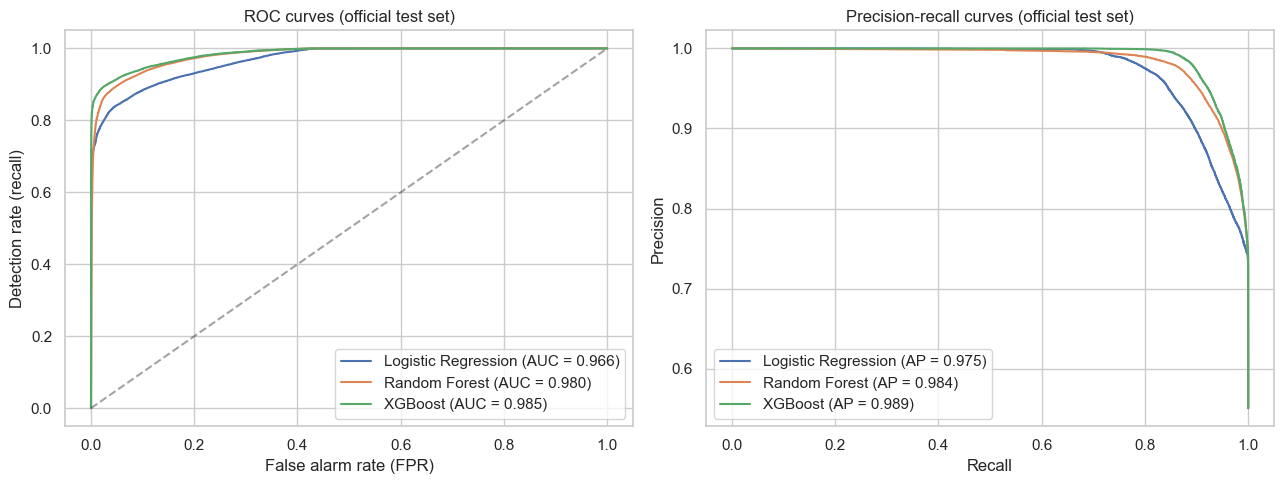

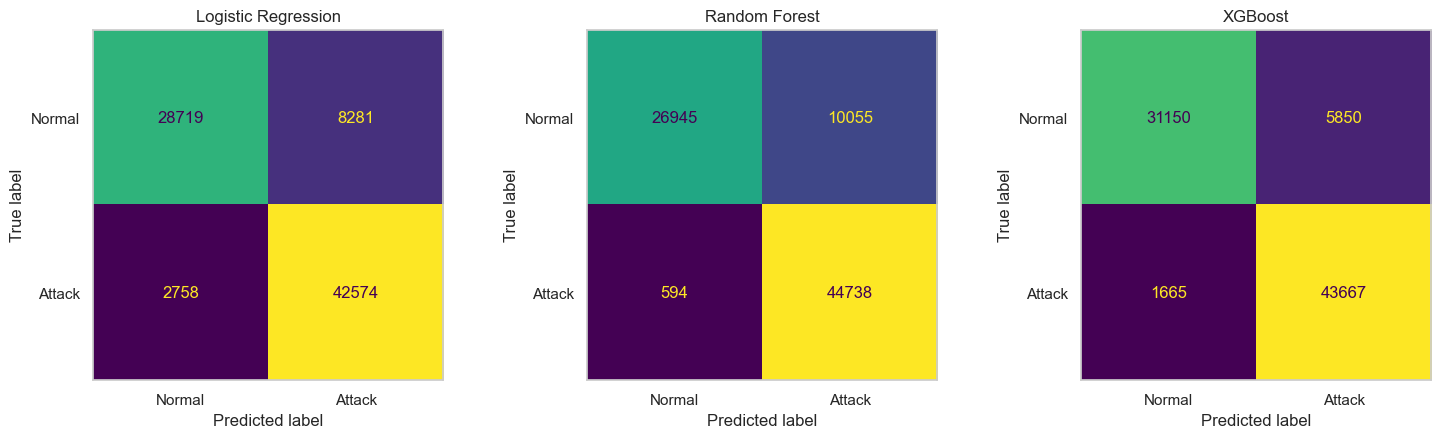

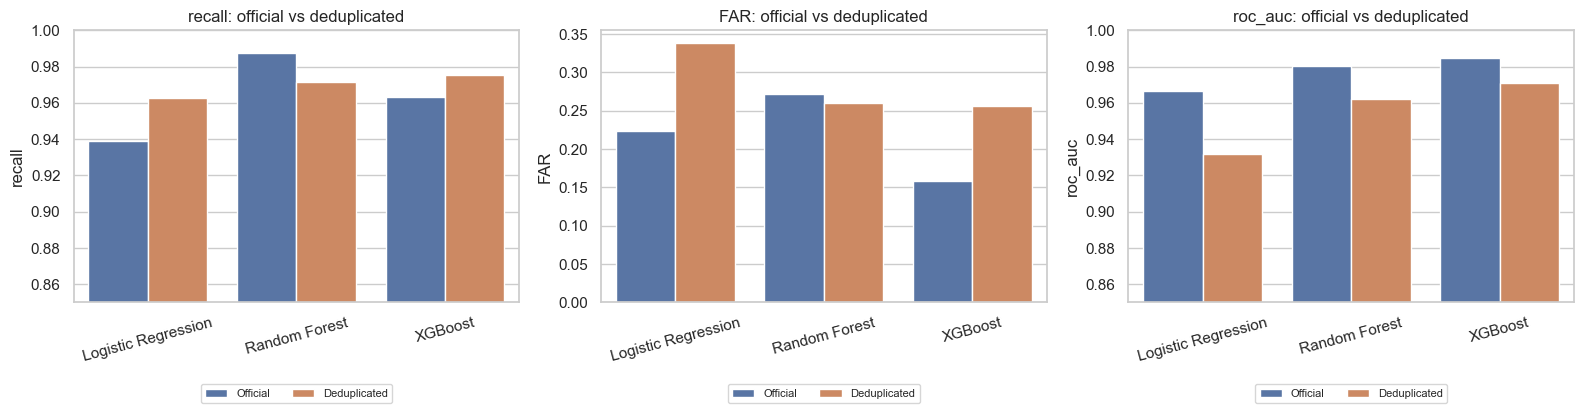

In [14]:
from sklearn.metrics import (roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)

# Stored predictions from Stages 3c and 4 (no retraining needed)
preds = {"Logistic Regression": (lr_pred, lr_score),
         "Random Forest": (rf_pred, rf_score),
         "XGBoost": (xgb_pred, xgb_score)}

# 1. Final metrics table (official split, seed 42), built straight from the predictions
table = pd.DataFrame({name: metrics(yte, pred, score)
                      for name, (pred, score) in preds.items()}).T.round(4)
table.index.name = "model"
display(table)
table.to_csv("results_official_seed42.csv")

# 2. ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (pred, score) in preds.items():
    fpr, tpr, _ = roc_curve(yte, score)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yte, score):.3f})")
    prec, rec, _ = precision_recall_curve(yte, score)
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(yte, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False alarm rate (FPR)", ylabel="Detection rate (recall)",
            title="ROC curves (official test set)")
axes[1].set(xlabel="Recall", ylabel="Precision",
            title="Precision-recall curves (official test set)")
axes[0].legend(loc="lower right")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.savefig("fig_roc_pr.png", dpi=200)
plt.show()

# 3. Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, (pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=["Normal", "Attack"],
                                            ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
    ax.grid(False)          # removes the grid lines drawn over the numbers
plt.tight_layout()
plt.savefig("fig_confusion.png", dpi=200)
plt.show()

# 4. Official versus deduplicated (mean over seeds, from the Stage 5 experiment)
mean_tbl = all_runs.drop(columns="seed").groupby(["setting", "model"]).mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ["recall", "FAR", "roc_auc"]):
    sns.barplot(data=mean_tbl, x="model", y=metric, hue="setting",
                hue_order=["Official", "Deduplicated"], ax=ax)
    ax.set_title(f"{metric}: official vs deduplicated")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=8)   # legend below the axes
    if metric in ("recall", "roc_auc"):
        ax.set_ylim(0.85, 1.0)      # truncated axis, so say so in the report caption
plt.tight_layout()
plt.savefig("fig_official_vs_dedup.png", dpi=200, bbox_inches="tight")
plt.show()

**Validation note:**
- **Checked:** the table against Stages 4 and 5; the figure values against the table.
- **Found:** AUCs 0.966, 0.980, 0.985 and confusion counts match; XGBoost has the lowest FAR and Random Forest the highest recall.
- **Why it matters:** high AUC with lower accuracy suggests the default 0.5 threshold is a poor operating point (a hypothesis, examined in Stage 7c).

## Stage 7: Investigation
**Goal:** Find out (a) which attack categories each model misses, (b) which features drive XGBoost and Random Forest, and (c) how the detection-versus-false-alarm trade-off changes when the decision threshold is chosen on a validation split instead of defaulting to 0.5.

**Prompt given to GenAI:**
"Using `te_cat` (test attack categories, never used as a feature), my stored predictions in `preds`, and `yte`: (1) compute per-category detection rate for each model (for Normal, the share correctly passed) with sample counts, and plot it as a horizontal bar chart; (2) plot the top 15 feature importances for XGBoost and Random Forest using `feat_names`; (3) split the deduplicated training data 80/20 (stratified) into train and validation, train XGBoost on the 80%, choose the threshold on the validation set that gives false alarm rates of 20%, 10%, 5% and 2%, and report recall and false alarm rate at each threshold on both the official and deduplicated test sets."

### Stage 7a: Per-category detection

model,n_test,Logistic Regression,Random Forest,XGBoost
category,,,,
Fuzzers,6062,0.691,0.910,0.755
Normal,37000,0.776,0.728,0.842
Analysis,677,0.914,1.000,0.950
Shellcode,378,0.966,0.992,0.981
Exploits,11132,0.944,0.996,0.991
DoS,4089,0.974,0.999,0.994
Backdoor,583,0.985,1.000,0.998
Reconnaissance,3496,0.985,1.000,0.998
Generic,18871,0.999,1.000,1.000


Test rows covered: 82332 (should equal 82332 )


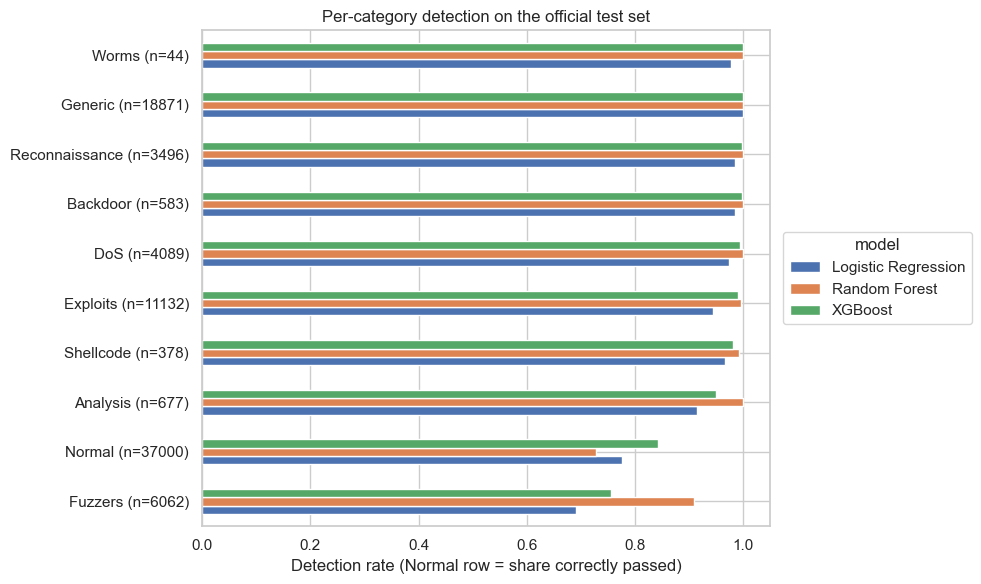

In [15]:
assert len(te_cat) == len(yte), "te_cat does not line up with the test labels"

rows = []
for name, (pred, _) in preds.items():
    for cat in pd.unique(te_cat):
        m = (te_cat == cat)
        # Attacks: share flagged as attack. Normal: share correctly passed (1 - FAR)
        rate = (pred[m] == 0).mean() if cat == "Normal" else (pred[m] == 1).mean()
        rows.append({"model": name, "category": cat, "n": int(m.sum()), "rate": rate})
cat_df = pd.DataFrame(rows)

pivot = cat_df.pivot(index="category", columns="model", values="rate").round(3)
pivot.insert(0, "n_test", cat_df[cat_df.model == "XGBoost"].set_index("category")["n"])
pivot = pivot.sort_values("XGBoost")
display(pivot)
print("Test rows covered:", int(pivot["n_test"].sum()), "(should equal", len(yte), ")")

# Plot: sample size in each label, legend outside the bars
plot_df = pivot.drop(columns="n_test").copy()
plot_df.index = [f"{c} (n={n})" for c, n in zip(pivot.index, pivot["n_test"])]

ax = plot_df.plot(kind="barh", figsize=(10, 6))
ax.set_xlabel("Detection rate (Normal row = share correctly passed)")
ax.set_ylabel("")
ax.set_title("Per-category detection on the official test set")
ax.legend(title="model", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig("fig_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

**Validation note:**
- **Checked:** category counts sum to the test size; the Normal row equals 1 − FAR.
- **Found:** 82,332 rows covered; Fuzzers weakest (LR 0.691, RF 0.910, XGBoost 0.755); other categories near 0.94 to 1.00.
- **Why it matters:** overall recall hides this weak category, and small categories (Worms, 44 rows) are only rough estimates.

**Derived figure for the report (Fuzzers share of XGBoost's missed attacks):**

In [16]:
missed = (yte == 1) & (xgb_pred == 0)
fuzz_missed = int(((te_cat == "Fuzzers") & missed).sum())
print(f"XGBoost missed attacks: {int(missed.sum())}, of which Fuzzers: {fuzz_missed} ({fuzz_missed / missed.sum():.1%})")

XGBoost missed attacks: 1665, of which Fuzzers: 1487 (89.3%)


### Stage 7b: Feature importance

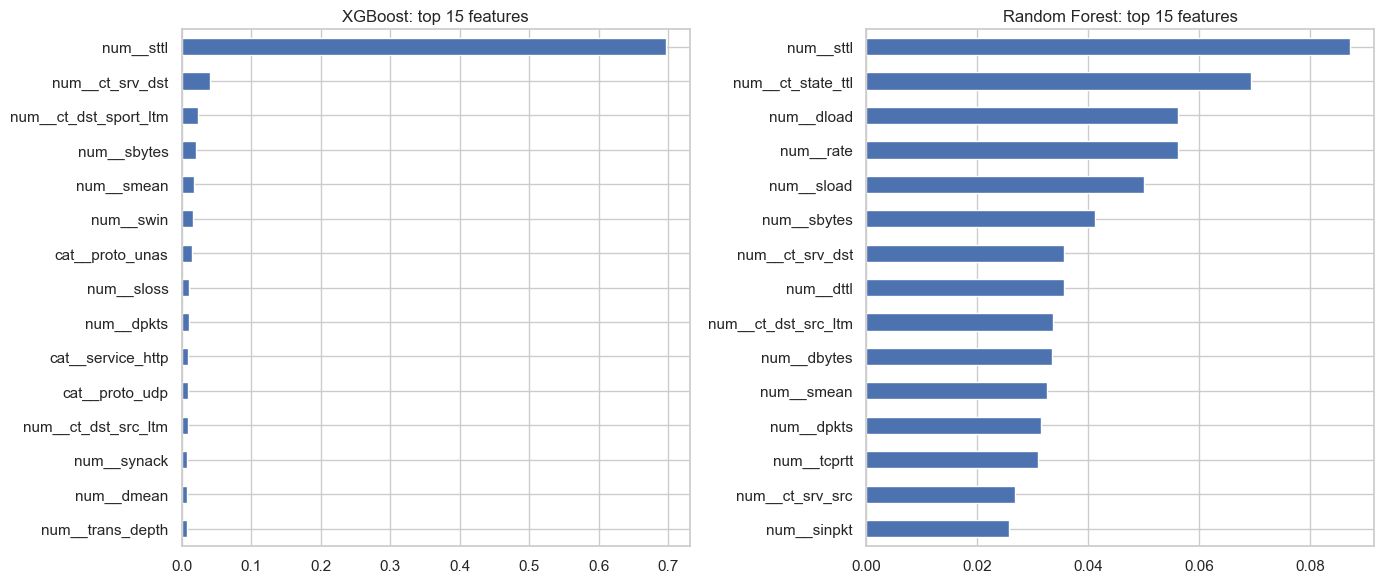

In [17]:
assert len(feat_names) == len(xgb.feature_importances_) == len(rf.feature_importances_)

imp_xgb = pd.Series(xgb.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
imp_rf = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp_xgb.iloc[::-1].plot(kind="barh", ax=axes[0], title="XGBoost: top 15 features")
imp_rf.iloc[::-1].plot(kind="barh", ax=axes[1], title="Random Forest: top 15 features")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=200)
plt.show()

**Validation note:**
- **Checked:** feature names align with the model importances.
- **Found:** `sttl` carries about 70% of XGBoost's importance; Random Forest is more spread out (`ct_state_ttl`, `dload`, `rate`).
- **Why it matters:** importance shows reliance, not causation; Stage 7d tests whether the model depends on the TTL features.

### Stage 7c: Threshold analysis

In [18]:
from sklearn.model_selection import train_test_split

# Thresholds are chosen on a validation split of the deduplicated TRAINING data, never on a test set
Xa, Xv, ya, yv = train_test_split(Xtr_d, ytr_d, test_size=0.2, stratify=ytr_d, random_state=SEED)
neg, pos = np.bincount(ya)
xgb_v = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, eval_metric="logloss",
                      scale_pos_weight=neg / pos, n_jobs=-1, random_state=SEED)
xgb_v.fit(Xa, ya)
sv = xgb_v.predict_proba(Xv)[:, 1]

def rates(y_true, score, thr):
    pred = (score > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return tp / (tp + fn), fp / (fp + tn)

test_sets = {"Official test": (Xte_o, yte_o), "Deduplicated test": (Xte_d, yte_d)}
scores = {k: xgb_v.predict_proba(X)[:, 1] for k, (X, y) in test_sets.items()}

rows = []
for target in [None, 0.20, 0.10, 0.05, 0.02]:
    # Threshold = score level that lets ~target of VALIDATION normal flows through as alerts
    thr = 0.5 if target is None else float(np.quantile(sv[yv == 0], 1 - target))
    row = {"target FAR (validation)": "default 0.5" if target is None else f"{target:.0%}",
           "threshold": round(thr, 4)}
    for k, (X, y) in test_sets.items():
        rec, far = rates(y, scores[k], thr)
        row[f"{k} recall"], row[f"{k} FAR"] = round(rec, 4), round(far, 4)
    rows.append(row)
display(pd.DataFrame(rows))

,target FAR (validation),threshold,Official test recall,Official test FAR,Deduplicated test recall,Deduplicated test FAR
0,default 0.5,0.5000,0.7021,0.2623,0.9724,0.2534
1,20%,0.0039,0.9091,0.4014,1.0000,0.4320
2,10%,0.4510,0.7059,0.2683,0.9809,0.2869
3,5%,0.6246,0.6768,0.2268,0.9410,0.1740
4,2%,0.7910,0.6051,0.1445,0.8723,0.0854


**Validation note:**
- **Checked:** the default row against Stage 5; thresholds chosen on a validation split, not the test set.
- **Found:** a 2% target FAR gave 8.5% on the deduplicated test set and 14.5% on the official one; the deduplicated-trained model had recall 0.7021 on the official test set at the default threshold.
- **Why it matters:** validation thresholds did not transfer (distribution shift is a hypothesis), and this comparison is confounded by training-set size.

### Stage 7d: Feature ablation (TTL features)
**Goal:** Stage 7b showed that `sttl` carries about 70% of XGBoost's importance, and that other TTL-related features (`dttl`, `ct_state_ttl`) rank highly for Random Forest. Test whether performance depends on them by retraining without them.

**Prompt given to GenAI:**
"Using the log-transformed matrices `Xtr` and `Xte`, my `feat_names` list and my `metrics()` function, retrain XGBoost (same settings as Stage 4, scale_pos_weight = negatives/positives, random_state=SEED) in three variants: (1) all features, (2) without `sttl`, (3) without `sttl`, `dttl` and `ct_state_ttl`. Select columns by matching the feature name after the double underscore, print which columns were dropped and how many remain, and show accuracy, precision, recall, F1, ROC-AUC and false alarm rate for each variant in one table."

In [19]:
def drop_features(names_to_drop):
    drop_idx = [i for i, n in enumerate(feat_names) if n.split("__")[-1] in names_to_drop]
    keep_idx = [i for i in range(len(feat_names)) if i not in drop_idx]
    return keep_idx, [feat_names[i] for i in drop_idx]

variants = {
    "All features": [],
    "Without sttl": ["sttl"],
    "Without sttl, dttl, ct_state_ttl": ["sttl", "dttl", "ct_state_ttl"],
}

neg, pos = np.bincount(ytr)
rows = []
for label, to_drop in variants.items():
    keep_idx, dropped = drop_features(to_drop)
    print(f"{label}: dropped {dropped} -> {len(keep_idx)} of {len(feat_names)} columns remain")
    m = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, eval_metric="logloss",
                      scale_pos_weight=neg / pos, n_jobs=-1, random_state=SEED)
    m.fit(Xtr[:, keep_idx], ytr)
    pred = m.predict(Xte[:, keep_idx])
    score = m.predict_proba(Xte[:, keep_idx])[:, 1]
    rows.append({"features": label, **metrics(yte, pred, score)})

ablation = pd.DataFrame(rows).round(4)
display(ablation)

All features: dropped [] -> 194 of 194 columns remain
Without sttl: dropped ['num__sttl'] -> 193 of 194 columns remain
Without sttl, dttl, ct_state_ttl: dropped ['num__sttl', 'num__dttl', 'num__ct_state_ttl'] -> 191 of 194 columns remain


,features,accuracy,precision,recall,f1,roc_auc,FAR
0,All features,0.9087,0.8819,0.9633,0.9208,0.9848,0.1581
1,Without sttl,0.9070,0.8818,0.9599,0.9192,0.9840,0.1577
2,"Without sttl, dttl, ct_state_ttl",0.9041,0.8812,0.9544,0.9164,0.9822,0.1576


**Validation note:**
- **Checked:** "All features" reproduces Stage 4; the dropped columns and remaining counts.
- **Found:** removing `sttl`, `dttl` and `ct_state_ttl` lowered accuracy from 0.9087 to 0.9041 and recall from 0.9633 to 0.9544.
- **Why it matters:** the model does not depend on these features alone (correlated features likely compensate); evasion by an attacker was not tested.

## Summary of results
- **Best on the official split:** XGBoost (accuracy 0.9087, FAR 0.1581, ROC-AUC 0.9848); Random Forest has the highest recall (0.9869) but the highest FAR (0.2718); the fixed Logistic Regression baseline reached 0.8659 accuracy.
- **Deduplication:** test attack share fell from 55.1% to 36.1%, FAR rose for XGBoost (0.1581 to 0.2562) and Logistic Regression, and XGBoost's lead over Random Forest almost disappeared.
- **Other findings:** Fuzzers were the hardest category, validation-chosen thresholds did not transfer, and removing the TTL features changed performance little.